# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Oscar Moulet  Student ID: B00821262
2. Full name: Adrien Labergere  Student ID: B00822082
3. Full name: Lucas Magret Delord  Student ID: B00819377
4. Full name: Louis Bettelli  Student ID: B00820941

**Project role (consultant / data scientist / risk analyst):** Risk analyst (Climate Risk Analyst, finance / quant)
**Key quantity (one sentence, with unit):** The annual EU ETS carbon cost of the aviation and cement sectors (verified emissions x average EU ETS auction price), in EUR bn per year; it is the main driver of our Climate Exposure & Mispricing Score.
**Repo URL:** https://github.com/Coachbet/moulet-labergere-magret_delord-bettelli

## Setup (given)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False   # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [2]:
if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    # EU ETS auction price (ICAP Allowance Price Explorer, primary market, EUR/t): daily -> yearly mean
    icap = pd.read_csv("data/icap-graph-price-data-2005-01-01-2026-10-25.csv", header=1)
    daily = pd.DataFrame({
        "year": pd.to_datetime(icap["Date"]).dt.year,
        "price": icap.iloc[:, 4].fillna(icap.iloc[:, 9]),   # col 4: EU ETS until 2018, col 9: EU ETS from 2019
    }).dropna()
    price = daily[daily["year"] <= 2025].groupby("year")["price"].mean()   # 2026 is not complete yet

    # EU ETS verified emissions by sector (EEA, EU Transaction Log), MtCO2
    ets = pd.read_csv("data/eu-ets-sector-emissions.csv")
    ets = ets[ets["sector"].isin(["10 Aviation", "29 Production of cement clinker"])]
    emissions = ets.groupby("year")["emissions_mt"].sum(min_count=2)    # both sectors (aviation only from 2012)

    inputs = pd.concat({"emissions_mt": emissions, "price_eur": price}, axis=1).dropna()
    inputs.index = inputs.index.astype(int)
    series = pd.DataFrame({
        "year": inputs.index,
        "value": (inputs["emissions_mt"] * inputs["price_eur"] / 1000).to_numpy(),  # Mt x EUR/t = EUR m -> EUR bn
    })
    NAME, UNIT = "EU ETS carbon cost, aviation + cement", "EUR bn"
series.tail()

,year,value
9,2021,7.60
10,2022,12.38
11,2023,12.47
12,2024,9.89
13,2025,9.96


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

Our key quantity is the annual EU ETS carbon cost of the aviation and cement sectors, i.e. verified emissions (EEA) times the average EU ETS auction price (ICAP), in EUR bn per year over 2012-2025. As climate risk analysts, we use it to decide how hard to stress the EBITDA of each company in our Climate Exposure & Mispricing Score, and therefore which companies look mispriced. Its main sources of uncertainty are:

* **A** (aleatoric): the year-to-year volatility of the carbon price, and activity shocks such as COVID for aviation in 2020.
* **E** (epistemic): how fast cement plants and airlines will abate, and how much of the cost is really paid after free allocation.
* **S** (scenario): the policy path (MSR tightening, CBAM and the phase-out of free allocation, scope of the ETS for aviation).

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [3]:
def fit_predict(train, horizon, model, level=0.90):
    """Fit on `train` (columns year, value) and predict the next `horizon` years.
    Returns year, mean, lo, hi, where [lo, hi] is a prediction interval at `level`."""
    years = train["year"].to_numpy(dtype=float)
    y = train["value"].to_numpy(dtype=float)
    if model == "loglinear":
        if (y <= 0).any():
            raise ValueError("loglinear needs all values > 0")
        y = np.log(y)
    elif model != "linear":
        raise ValueError("model must be 'linear' or 'loglinear'")

    n = len(y)
    x_mean = years.mean()
    X = np.column_stack([np.ones(n), years - x_mean])        # centred year
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    s2 = resid @ resid / (n - 2)                              # residual variance
    t_crit = stats.t.ppf(0.5 + level / 2, df=n - 2)

    future = years.max() + np.arange(1, horizon + 1)
    X0 = np.column_stack([np.ones(horizon), future - x_mean])
    mean = X0 @ beta
    leverage = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)      # x0' (X'X)^-1 x0
    half = t_crit * np.sqrt(s2 * (1 + leverage))              # prediction interval (not a CI)
    lo, hi = mean - half, mean + half
    if model == "loglinear":                                  # back to the original scale
        mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)   # (mean is then the median)
    return pd.DataFrame({"year": future.astype(int), "mean": mean, "lo": lo, "hi": hi})


H = 5                                                         # hold out the last 5 years
train, test = series.iloc[:-H], series.iloc[-H:]

parts = []
for m in ["linear", "loglinear"]:
    pred = fit_predict(train, H, m)
    pred["model"] = m
    parts.append(pred)

backtest = pd.concat(parts, ignore_index=True).merge(
    test.rename(columns={"value": "actual"}), on="year")
backtest["inside"] = (backtest["actual"] >= backtest["lo"]) & (backtest["actual"] <= backtest["hi"])
backtest[["model", "year", "actual", "mean", "lo", "hi", "inside"]]

,model,year,actual,mean,lo,hi,inside
0,linear,2021,7.60,3.91,1.66,6.15,False
1,linear,2022,12.38,4.29,1.92,6.67,False
2,linear,2023,12.47,4.68,2.16,7.20,False
3,linear,2024,9.89,5.07,2.39,7.75,False
4,linear,2025,9.96,5.46,2.61,8.31,False
5,loglinear,2021,7.60,3.97,1.37,11.46,True
6,loglinear,2022,12.38,4.75,1.55,14.60,True
7,loglinear,2023,12.47,5.70,1.73,18.75,True
8,loglinear,2024,9.89,6.83,1.92,24.22,True
9,loglinear,2025,9.96,8.18,2.13,31.44,True


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

In [4]:
# (a) held-out years inside the 90% band
hits = backtest.groupby("model")["inside"].sum()
print("Held-out years inside the 90% band (out of 5):")
print(hits.to_string())

# (b) if the band were really 90%, a miss happens with p = 0.1: P(X >= k) for X ~ Bin(5, 0.1)
k = np.arange(0, 6)
binom_tail = pd.DataFrame({"k misses": k, "P(X >= k)": stats.binom.sf(k - 1, 5, 0.1)})
binom_tail["P(X >= k)"] = binom_tail["P(X >= k)"].map("{:.4f}".format)
binom_tail

Held-out years inside the 90% band (out of 5):
model
linear       0
loglinear    5


,k misses,P(X >= k)
0,0,1.0000
1,1,0.4095
2,2,0.0815
3,3,0.0086
4,4,0.0005
5,5,0.0000


**Your answer (Q2):**

**(a)** The linear model has **0 of 5** held-out years (2021-2025) inside its 90% band, while the log-linear model has **5 of 5**.

**(b)** If the band were really 90%, each year is a miss with probability 0.1. With 2 misses, P(X >= 2) = 0.08, which is already a bit suspicious, and with 3 misses P(X >= 3) = 0.009, so I would clearly doubt the band from 3 misses. The linear model has 5 misses (P(X >= 5) = 0.00001), so its band is clearly not calibrated; the log-linear model has no miss, which is consistent with 90%.

**(c)** I keep the log-linear model, since it is the only one whose band holds. However, it holds mostly because it is very wide (2.1 to 31.4 EUR bn in 2025), and its central value is still below the truth every year (8.2 vs 10.0 EUR bn in 2025). The gap between the two models comes from the price jump after the 2018 MSR reform and in 2021: a trend fitted on 2012-2020 cannot see a policy break like this. So model choice is a big source of uncertainty here, and I do not use the failed linear trend in Part F.

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [5]:
# Rolling origin: train on the first `end` years (at least 10), predict 1 to 3 years ahead
rows = []
for end in range(10, len(series)):
    tr = series.iloc[:end]
    h_max = min(3, len(series) - end)               # only horizons for which the truth is known
    for m in ["linear", "loglinear"]:
        pred = fit_predict(tr, h_max, m)
        pred["model"] = m
        pred["horizon"] = pred["year"] - tr["year"].iloc[-1]
        rows.append(pred)

rolling = pd.concat(rows, ignore_index=True).merge(
    series.rename(columns={"value": "actual"}), on="year")
rolling["inside"] = (rolling["actual"] >= rolling["lo"]) & (rolling["actual"] <= rolling["hi"])

coverage = (rolling.groupby(["model", "horizon"])["inside"]
            .agg(coverage="mean", n_tests="count").reset_index())
coverage["coverage"] = 100 * coverage["coverage"]
coverage.rename(columns={"coverage": "coverage (%)"})

,model,horizon,coverage (%),n_tests
0,linear,1,75.00,4
1,linear,2,66.67,3
2,linear,3,100.00,2
3,loglinear,1,100.00,4
4,loglinear,2,100.00,3
5,loglinear,3,100.00,2


---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [6]:
N = 5_000
TARGET_YEAR = 2030
H_C = TARGET_YEAR - inputs.index.max()          # 5 years after the last observed year (2025)


def compute_quantity(emissions_mt, price_eur):
    """Carbon cost (EUR bn) = verified emissions (MtCO2) x EU ETS price (EUR/t) / 1000."""
    return emissions_mt * price_eur / 1000


# Input 1, 2030 emissions of aviation + cement ~ Triangular(low, mode, high). We do not know the
# abatement pace, only a plausible range, so a Triangular is the natural choice:
#   mode = the 2025 level continued at its 2022-2025 trend,
#   low  = a pace 1.5 times faster (CBAM and the end of free allocation push cement to abate),
#   high = no further reduction (aviation traffic keeps growing and offsets cement).
e_2025 = inputs["emissions_mt"].iloc[-1]
g = (e_2025 / inputs.loc[2022, "emissions_mt"]) ** (1 / 3) - 1
e_low, e_mode, e_high = e_2025 * (1 + 1.5 * g) ** H_C, e_2025 * (1 + g) ** H_C, e_2025
emissions_2030 = rng.triangular(e_low, e_mode, e_high, N)

# Input 2, 2030 EU ETS price ~ Lognormal: a price cannot be negative and its changes are multiplicative.
# Median = 2025 average price (random walk, no drift); sigma = st. dev. of the annual log changes since
# the 2018 MSR reform, scaled by sqrt(5) for a 5-year horizon.
p_2025 = inputs["price_eur"].iloc[-1]
sigma_year = np.diff(np.log(inputs.loc[2018:, "price_eur"])).std(ddof=1)
price_2030 = p_2025 * np.exp(rng.normal(0, sigma_year * np.sqrt(H_C), N))

print(f"Emissions 2030 ~ Triangular({e_low:.1f}, {e_mode:.1f}, {e_high:.1f}) MtCO2  (2022-2025 trend: {g:.1%}/yr)")
print(f"Price 2030 ~ Lognormal(median {p_2025:.1f} EUR/t, sigma {sigma_year * np.sqrt(H_C):.2f})  (annual sigma {sigma_year:.2f})")

draws = compute_quantity(emissions_2030, price_2030)
q05, q50, q95 = np.percentile(draws, [5, 50, 95])
print(f"{TARGET_YEAR} {NAME}: median = {q50:,.1f} {UNIT}, 90% interval = [{q05:,.1f}, {q95:,.1f}] {UNIT}")


# One-at-a-time sensitivity: fix one input at its median, keep the other random
def summarise(x):
    lo, med, hi = np.percentile(x, [5, 50, 95])
    return med, lo, hi, 100 * (hi - lo) / 2 / med      # relative half-width in %


cases = {
    "Both inputs random": draws,
    "Emissions fixed at their median": compute_quantity(np.median(emissions_2030), price_2030),
    "Price fixed at its median": compute_quantity(emissions_2030, np.median(price_2030)),
}
sens = pd.DataFrame([summarise(x) for x in cases.values()], index=list(cases),
                    columns=["median", "5%", "95%", "relative half-width (%)"])
sens

Emissions 2030 ~ Triangular(97.5, 109.1, 135.5) MtCO2  (2022-2025 trend: -4.3%/yr)
Price 2030 ~ Lognormal(median 73.5 EUR/t, sigma 0.79)  (annual sigma 0.35)
2030 EU ETS carbon cost, aviation + cement: median = 8.2 EUR bn, 90% interval = [2.2, 31.3] EUR bn


,median,5%,95%,relative half-width (%)
Both inputs random,8.22,2.23,31.30,176.89
Emissions fixed at their median,8.16,2.23,30.74,174.64
Price fixed at its median,8.16,7.39,9.28,11.58


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

**(a)** For 2030 the median carbon cost is **8.2 EUR bn** and the 90% interval is **[2.2, 31.3] EUR bn**.

**(b)** Fixing the **carbon price** shrinks the interval the most: the relative half-width falls from 176.9% to 11.6%, while fixing emissions only brings it to 174.6%. In our model the price is mainly **aleatoric**, because we treat it as a random walk with the market volatility observed since 2018, even if part of it really comes from policy decisions.

**(c)** With one more week I would collect the EUA futures curve for December 2030, to anchor the median, and option-implied volatilities, instead of relying on only 7 annual price changes. I would also collect installation-level emissions and free allocation for our companies. What would remain whatever we do is the market volatility of the price and the policy path (scenario uncertainty), which no dataset can remove.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [7]:
# Scenarios change the price input of Part C; emissions draws and price volatility stay the same.
#  - Baseline: the Part C draws (2025 price, no drift)
#  - Low price: 50 EUR/t in 2030, weak policy (supply is not tightened further)
#  - High price: 150 EUR/t in 2030, fast transition (the 50 vs 150 example of the lab, in EUR)
z = rng.normal(0, sigma_year * np.sqrt(H_C), N)
scenario_draws = {
    "Baseline (2025 price, no drift)": draws,
    "Low price (50 EUR/t in 2030)": compute_quantity(emissions_2030, 50 * np.exp(z)),
    "High price (150 EUR/t in 2030)": compute_quantity(emissions_2030, 150 * np.exp(z)),
}

rows = []
for name, d in scenario_draws.items():
    lo, med, hi = np.percentile(d, [5, 50, 95])
    rows.append({"scenario": name, "median": med, "5%": lo, "95%": hi, "width": hi - lo})
scen = pd.DataFrame(rows).set_index("scenario")

gap = scen["median"].max() - scen["median"].min()
print(f"Largest gap between scenario medians: {gap:,.1f} {UNIT}")
print(f"Interval width within one scenario:   {scen['width'].min():,.1f} to {scen['width'].max():,.1f} {UNIT}")
scen

Largest gap between scenario medians: 11.1 EUR bn
Interval width within one scenario:   20.4 to 61.3 EUR bn


,median,5%,95%,width
scenario,,,,
"Baseline (2025 price, no drift)",8.22,2.23,31.30,29.07
Low price (50 EUR/t in 2030),5.56,1.55,21.99,20.44
High price (150 EUR/t in 2030),16.68,4.65,65.97,61.32


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

The largest gap between scenario medians is **11.1 EUR bn** (16.7 EUR bn at 150 EUR/t vs 5.6 EUR bn at 50 EUR/t), while the 90% interval inside one scenario is **20.4 to 61.3 EUR bn** wide (29.1 EUR bn in the baseline). So the width within a scenario is bigger than the gap between scenarios, and all the bands overlap a lot. This means that market volatility matters more than the scenario choice for this quantity. I would still show one band per scenario on the same fan chart, so that the reader sees the overlap, but the main message is the range itself, not the scenario ranking.

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [ ]:
# your code here (optional)

**Your answer (Q5):**

Not applicable: our project does not use any variable that can only be obtained from text. Our inputs (verified emissions, carbon prices, market data) all come from structured datasets, so we skip this optional part.

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

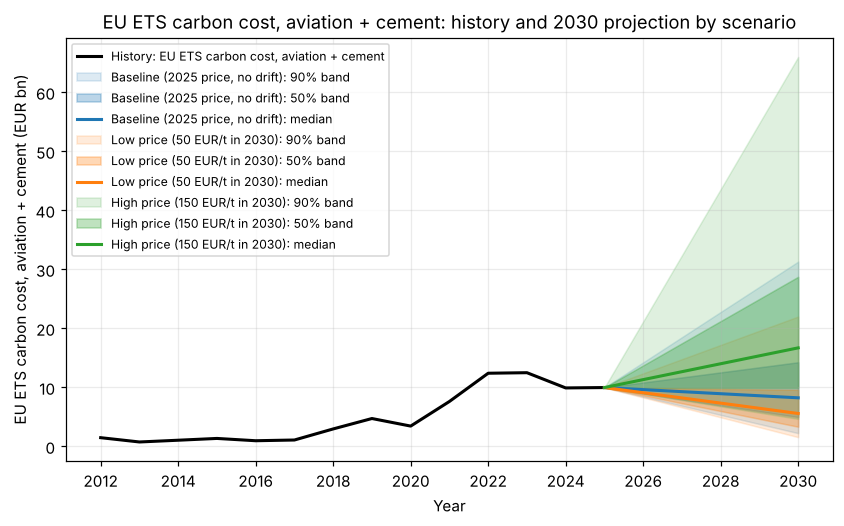

In [9]:
last_year, last_value = int(series["year"].iloc[-1]), series["value"].iloc[-1]
path_years = np.arange(last_year, TARGET_YEAR + 1)
frac = (path_years - last_year) / (TARGET_YEAR - last_year)   # 0 today -> 1 in the target year


def widen(q):
    # the band starts at today's value and widens linearly to the Part C/D quantile in 2030
    return last_value + (q - last_value) * frac


colors = ["tab:blue", "tab:orange", "tab:green"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(series["year"], series["value"], color="black", lw=2, label=f"History: {NAME}")
for (name, d), c in zip(scenario_draws.items(), colors):
    p5, p25, p50, p75, p95 = np.percentile(d, [5, 25, 50, 75, 95])
    ax.fill_between(path_years, widen(p5), widen(p95), color=c, alpha=0.15, label=f"{name}: 90% band")
    ax.fill_between(path_years, widen(p25), widen(p75), color=c, alpha=0.30, label=f"{name}: 50% band")
    ax.plot(path_years, widen(p50), color=c, lw=2, label=f"{name}: median")
ax.set_xticks(np.arange(series["year"].min(), TARGET_YEAR + 1, 2))
ax.set_xlabel("Year")
ax.set_ylabel(f"{NAME} ({UNIT})")
ax.set_title(f"{NAME}: history and {TARGET_YEAR} projection by scenario")
ax.legend(fontsize=8, loc="upper left")
fig.savefig("fig_uncertainty.png", dpi=200, bbox_inches="tight")
plt.show()

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

We project the 2030 EU ETS carbon cost of the aviation and cement sectors (verified emissions times the average auction price) under three price scenarios. In the baseline, which keeps the 2025 price with no drift, the median is EUR 8.2 bn and the 90% interval is EUR 2.2-31.3 bn, so under our assumptions the cost is very likely to stay below EUR 31 bn. The carbon price drives the range: fixing it cuts the relative half-width from 177% to 12%. The largest scenario gap (EUR 11.1 bn, 50 vs 150 EUR/t) is smaller than the width of any interval. In the back-test, 0 of 5 held-out years fell inside the linear band and 5 of 5 inside the wider log-linear band. One limitation is that we use the gross cost and ignore free allocation, which overstates the cost actually paid.

**Your answer (Q7):**

*"Because the range is this wide, the decision that changes is **that we cannot rank companies on a single carbon-cost number: we stress each company's EBITDA at the high end of the price range (150 EUR/t and above) before flagging it as mispriced**."*